# Scegliere il carattere da scrivere

*Anatomia di un LLM* · capitolo 7, «Generare» · nel libro: §7.3 «Scegliere il carattere» · script `06-03`, `scripts/06_03_campionatori.py`

**Dove siamo.** La seconda metà della generazione: fra novantatré percentuali, quale carattere prendere. Qui si confrontano temperatura e tagli sugli stessi numeri e poi sul testo.

Il modello dice quanto e' probabile ciascun carattere. Trasformare quelle
percentuali in una scelta e' un problema a se', e la manopola che tutti
chiamano "creativita'" e' in realta' un modo di deformare quella distribuzione
prima di pescarci dentro.

Si esegue con `python3 scripts/06_03_campionatori.py`
e dura circa 5 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

> **Questo notebook usa il modello addestrato.** Se `checkpoints/agogpt.pt` non c'è, la seconda cella ne scarica i pesi; per addestrarlo da te c'è `05_02_pretrain_agogpt`.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/06_03_campionatori.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [ ]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [ ]:
# Questo notebook usa il modello addestrato. Se non c'e', si scaricano i
# suoi pesi (7 MB) invece di addestrarlo: per addestrarlo davvero c'e' il
# notebook 05_02_pretrain_agogpt, che dura alcuni minuti.
import urllib.request

modello = Path("checkpoints") / "agogpt.pt"
if not modello.exists():
    modello.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://github.com/fcollova/llm-anatomy/releases/download/modello-v0.1/agogpt-pesi.pt", modello)

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch

from llm_anatomy.config import AgoGPTConfig
from llm_anatomy.data import tokenizer_corpus
from llm_anatomy.model import AgoGPT
from llm_anatomy.sample import genera, min_p, temperatura, top_k, top_p
from llm_anatomy.train import carica_checkpoint
from llm_anatomy.utils import (dec, figura, percorso, prepara, stile_figure,
                               tabella, titolo, verifica)

prepara()

file_ckpt = percorso("checkpoints", "agogpt.pt")
if not file_ckpt.exists():
    raise SystemExit("checkpoint assente: eseguire prima 05-02")
stato = carica_checkpoint(file_ckpt)
cfg = AgoGPTConfig(**stato["cfg"])
modello = AgoGPT(cfg)
modello.load_state_dict(stato["modello"])
modello.eval()
tok = tokenizer_corpus()


def simbolo(i) -> str:
    c = tok.itos[int(i)]
    return {"\n": "'\\n'", " ": "'sp'"}.get(c, repr(c))


def descrivi(logits: torch.Tensor) -> tuple[int, float]:
    """Quanti simboli restano in gioco e quanta massa originale conservano."""
    vivi = int((logits > float("-inf")).sum())
    p = logits.softmax(dim=-1)
    return vivi, float(p.max())

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337


### Tre momenti diversi, tre distribuzioni

> **Nel libro, §7.3 «Scegliere il carattere».** Fra novantatré percentuali, quale carattere si prende?

**Cosa guardare.** L'entropia: quasi zero dopo `parmigian`, alta a inizio riga.

In [ ]:
titolo("Tre momenti diversi, tre distribuzioni")
contesti = {
    "dopo 'parmigian'": "parmigian",
    "dopo 'Mettete al fuoco un'": "Mettete al fuoco un",
    "a inizio riga": "\n",
}
logit_per_contesto = {}
for nome, testo in contesti.items():
    idx = torch.tensor([tok.encode(testo)])
    with torch.no_grad():
        logits, _ = modello(idx)
    l = logits[0, -1]
    logit_per_contesto[nome] = l
    p = l.softmax(dim=-1)
    entropia = float(-(p * (p + 1e-12).log()).sum())
    top = p.topk(3)
    print(f"  {nome}")
    print(f"    entropia {dec(entropia, 3)} nat, prime tre: "
          + ", ".join(f"{simbolo(i)} {dec(float(v), 3)}"
                      for v, i in zip(top.values, top.indices)))


Tre momenti diversi, tre distribuzioni
--------------------------------------
  dopo 'parmigian'
    entropia 0,006 nat, prime tre: 'o' 0,999, 'a' 0,000, 'e' 0,000
  dopo 'Mettete al fuoco un'
    entropia 1,539 nat, prime tre: 'sp' 0,418, 'i' 0,309, 'a' 0,099
  a inizio riga
    entropia 3,330 nat, prime tre: 'sp' 0,172, 'p' 0,081, 's' 0,081


### Gli stessi numeri, sette modi di tagliarli

**Cosa guardare.** La colonna `simboli in gioco`: 5 per il top-k, 29 per il top-p, 17 per il min-p.

**Prova a cambiare:** nel top-k porta 5 a 20.

<details><summary>Che cosa succede</summary>

Restano 20 simboli in gioco e la probabilità del migliore scende da 0,383 a 0,212: più candidati, ciascuno con meno peso.

</details>

In [ ]:
titolo("Gli stessi numeri, sette modi di tagliarli")
l = logit_per_contesto["a inizio riga"]
righe = []
for nome, filtrati in (
    ("nessun filtro", l),
    ("temperatura 0,7", temperatura(l, 0.7)),
    ("temperatura 1,5", temperatura(l, 1.5)),
    ("greedy (T=0)", temperatura(l, 0.0)),
    ("top-k = 5", top_k(l, 5)),
    ("top-p = 0,9", top_p(l, 0.9)),
    ("min-p = 0,1", min_p(l, 0.1)),
):
    vivi, massa = descrivi(filtrati)
    p = filtrati.softmax(dim=-1)
    top = p.topk(2)
    righe.append([nome, vivi, dec(massa, 3),
                  " ".join(f"{simbolo(i)}" for i in top.indices)])
tabella(["filtro", "simboli in gioco", "prob. del migliore", "primi due"],
        righe)
print(f"  il vocabolario ha {cfg.vocab_size} simboli: la colonna 'in gioco'")
print("  dice quanti ne restano dopo il taglio")


Gli stessi numeri, sette modi di tagliarli
------------------------------------------
filtro           simboli in gioco  prob. del migliore  primi due
---------------  ----------------  ------------------  ---------
nessun filtro                  93               0,172   'sp' 'p'
temperatura 0,7                93               0,301   'sp' 'p'
temperatura 1,5                93               0,094   'sp' 'p'
greedy (T=0)                    1               1,000   'sp' 'p'
top-k = 5                       5               0,383   'sp' 'p'
top-p = 0,9                    29               0,191   'sp' 'p'
min-p = 0,1                    17               0,224   'sp' 'p'
  il vocabolario ha 93 simboli: la colonna 'in gioco'
  dice quanti ne restano dopo il taglio


### Perché un taglio fisso non va bene sempre

*Questa parte non è stampata nel libro.*

**Cosa guardare.** Il top-k tiene sempre cinque simboli; il min-p uno solo quando il modello è sicuro, diciassette quando è incerto.

In [ ]:
titolo("Perche' un taglio fisso non va bene sempre")
righe = []
for nome in contesti:
    l = logit_per_contesto[nome]
    p = l.softmax(dim=-1)
    entropia = float(-(p * (p + 1e-12).log()).sum())
    vivi_k, _ = descrivi(top_k(l, 5))
    vivi_p, _ = descrivi(top_p(l, 0.9))
    vivi_m, _ = descrivi(min_p(l, 0.1))
    righe.append([nome[:26], dec(entropia, 2), vivi_k, vivi_p, vivi_m])
tabella(["contesto", "entropia", "top-k=5", "top-p=0,9", "min-p=0,1"], righe)
print("  top-k lascia sempre cinque simboli, che il modello sia sicuro o no.")
print("  min-p ne lascia pochi quando la distribuzione e' appuntita e molti")
print("  quando e' piatta: la soglia e' relativa al migliore, non assoluta")

vivi_min = [r[4] for r in righe]
verifica(max(vivi_min) > min(vivi_min),
         "min-p cambia il numero di candidati a seconda del contesto")
verifica(all(r[2] == 5 for r in righe),
         "top-k ne lascia esattamente cinque in ogni contesto")


Perche' un taglio fisso non va bene sempre
------------------------------------------
contesto                    entropia  top-k=5  top-p=0,9  min-p=0,1
--------------------------  --------  -------  ---------  ---------
dopo 'parmigian'                0,01        5          1          1
dopo 'Mettete al fuoco un'      1,54        5          5          4
a inizio riga                   3,33        5         29         17
  top-k lascia sempre cinque simboli, che il modello sia sicuro o no.
  min-p ne lascia pochi quando la distribuzione e' appuntita e molti
  quando e' piatta: la soglia e' relativa al migliore, non assoluta
  [verifica superata] min-p cambia il numero di candidati a seconda del
                      contesto
  [verifica superata] top-k ne lascia esattamente cinque in ogni contesto


### L'effetto sul testo

**Cosa guardare.** La temperatura zero si ripete, quella alta inventa parole, con un taglio resta un ricettario.

**Prova a cambiare:** aggiungi la riga `("temperatura 0,3", dict(temp=0.3))`.

<details><summary>Che cosa succede</summary>

A 0,3 il testo è più regolare: `Prendete un pollastro della sua buca di vitella di latte`. Le altre righe non cambiano, perché ognuna riparte dallo stesso seme.

</details>

In [ ]:
titolo("L'effetto sul testo")
avvio = torch.tensor([tok.encode("Risotto coi funghi\n\n")])
impostazioni = [
    ("greedy", dict(temp=0.0)),
    ("temperatura 0,8", dict(temp=0.8)),
    ("temperatura 1,4", dict(temp=1.4)),
    ("temp 1,0 + top-k 10", dict(temp=1.0, k=10)),
    ("temp 1,0 + min-p 0,1", dict(temp=1.0, minp=0.1)),
]
for nome, kwargs in impostazioni:
    g = torch.Generator().manual_seed(7)
    uscita = genera(modello, avvio.clone(), 90, generatore=g, **kwargs)
    testo = tok.decode(uscita[0, avvio.shape[1]:]).replace("\n", " / ")
    print(f"  {nome}")
    print(f"    {testo[:70]}")


L'effetto sul testo
-------------------


  greedy
    Se vi servirete che si presta col mestolo e se non si presta che si / 


  temperatura 0,8
    Prendete un lingua agli altri più di Romagna di una chiara d'uovo. / L


  temperatura 1,4
    Prendete uova, gr. 900. /   VinoN. Pare — Vue, doratelo con un mazzett
  temp 1,0 + top-k 10
    Prendete un lingue. /   Rhum. /  / Le beccaccia e gl'ottorno da nuova,


  temp 1,0 + min-p 0,1
    Prendete un vaso o due dita e più di metallo di una chiara d'uovo. / L


### In pratica

*Questa parte non è stampata nel libro.*

**Cosa guardare.** La regola d'uso: una temperatura moderata e un taglio.

In [ ]:
titolo("In pratica")
print("  greedy si ripete, perche' sceglie sempre lo stesso continuo piu'")
print("  probabile; la temperatura alta senza tagli produce simboli rari e")
print("  parole inesistenti. I tagli servono a togliere la coda della")
print("  distribuzione senza appiattire cio' che resta, ed e' il motivo per")
print("  cui in produzione si combina quasi sempre una temperatura moderata")
print("  con un taglio, non l'una o l'altro")


In pratica
----------
  greedy si ripete, perche' sceglie sempre lo stesso continuo piu'
  probabile; la temperatura alta senza tagli produce simboli rari e
  parole inesistenti. I tagli servono a togliere la coda della
  distribuzione senza appiattire cio' che resta, ed e' il motivo per
  cui in produzione si combina quasi sempre una temperatura moderata
  con un taglio, non l'una o l'altro


### I tagli, disegnati

*Questa parte non è stampata nel libro.*

**Cosa guardare.** La figura: le percentuali in fila e dove si ferma ciascun taglio.


I tagli, disegnati
------------------
  top-k tiene 5 simboli, min-p 17, top-p 29


  [figura] outputs/figures/06-03_tagli.pdf


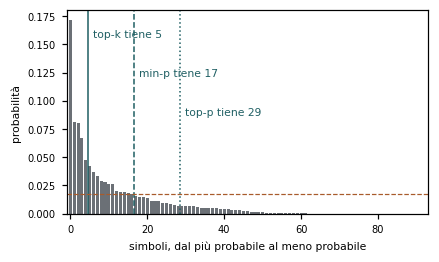

In [ ]:
# Le percentuali "a inizio riga", dalla piu' alta alla piu' bassa, e dove le
# taglia ciascun filtro: il top-k dopo un numero fisso di simboli, il top-p
# quando la somma arriva a 0,9, il min-p sotto un decimo del migliore.
titolo("I tagli, disegnati")
prob = logit_per_contesto["a inizio riga"].softmax(dim=-1).sort(descending=True).values
n_k = 5
n_p = int((prob.cumsum(0) - prob < 0.9).sum())
soglia_minp = 0.1 * float(prob[0])
n_minp = int((prob >= soglia_minp).sum())
fig, ax = plt.subplots(figsize=(stile_figure(), 2.4))
ax.bar(range(len(prob)), prob.tolist(), width=0.8, color="#6B7076")
tagli = ((n_k, f"top-k tiene {n_k}", "-", 0.95),
         (n_minp, f"min-p tiene {n_minp}", "--", 0.75),
         (n_p, f"top-p tiene {n_p}", ":", 0.55))
for n, nome, stile, altezza in tagli:
    ax.axvline(n - 0.5, color="#1F5F63", ls=stile, lw=1)
    ax.text(n + 0.8, float(prob[0]) * altezza, nome, color="#1F5F63", va="top")
ax.axhline(soglia_minp, color="#A85B2B", ls="--", lw=0.8)
ax.set_xlabel("simboli, dal più probabile al meno probabile")
ax.set_ylabel("probabilità")
ax.set_xlim(-1, len(prob))
print(f"  top-k tiene {n_k} simboli, min-p {n_minp}, top-p {n_p}")
figura(fig, "06-03_tagli")